In [1]:
import pandas as pd
import os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from pyclustering.cluster.clique import clique

In [2]:
ligamx = pd.read_csv('liga_mx_equipo_torneo.csv')

In [3]:
print("Dimensiones:", ligamx.shape)
print()
ligamx.info()
display(ligamx.head())
display(ligamx.describe())

Dimensiones: (307, 9)

<class 'pandas.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   equipo         307 non-null    str    
 1   torneo         307 non-null    str    
 2   partidos       307 non-null    int64  
 3   gf_pp          307 non-null    float64
 4   gc_pp          307 non-null    float64
 5   pts_pp         307 non-null    float64
 6   empates_pp     307 non-null    float64
 7   pts_visita_pp  307 non-null    float64
 8   pts_local_pp   307 non-null    float64
dtypes: float64(6), int64(1), str(2)
memory usage: 21.7 KB


,equipo,torneo,partidos,gf_pp,gc_pp,pts_pp,empates_pp,pts_visita_pp,pts_local_pp
0,Atlas,2016-Apertura,17,1.235294,1.470588,1.117647,0.411765,0.333333,2.000000
1,Atlas,2016-Clausura,17,1.411765,1.176471,1.529412,0.294118,1.375000,1.666667
2,Atlas,2017-Apertura,17,1.352941,1.117647,1.470588,0.235294,1.444444,1.500000
3,Atlas,2017-Clausura,17,1.000000,1.529412,1.058824,0.176471,0.250000,1.777778
4,Atlas,2018-Apertura,17,0.647059,1.588235,0.647059,0.294118,0.250000,1.000000


,partidos,gf_pp,gc_pp,pts_pp,empates_pp,pts_visita_pp,pts_local_pp
count,307.000000,307.000000,307.000000,307.000000,307.000000,307.000000,307.000000
mean,16.651466,1.330236,1.330236,1.366007,0.267987,1.132148,1.599075
std,1.680051,0.370371,0.370562,0.419643,0.112355,0.525300,0.545912
min,10.000000,0.411765,0.588235,0.235294,0.000000,0.000000,0.250000
25%,17.000000,1.079412,1.058824,1.058824,0.176471,0.750000,1.222222
50%,17.000000,1.294118,1.294118,1.352941,0.235294,1.125000,1.555556
75%,17.000000,1.529412,1.571895,1.647059,0.352941,1.500000,2.000000
max,18.000000,2.411765,2.529412,2.470588,0.647059,2.428571,3.000000


      gf_pp  gc_pp  empates_pp  pts_local_pp  pts_visita_pp
mean  0.000  0.000       0.000         0.000         -0.000
std   1.002  1.002       1.002         1.002          1.002

Filas con menos de 17 partidos: 18
torneo
2019-Clausura    18
Name: count, dtype: int64


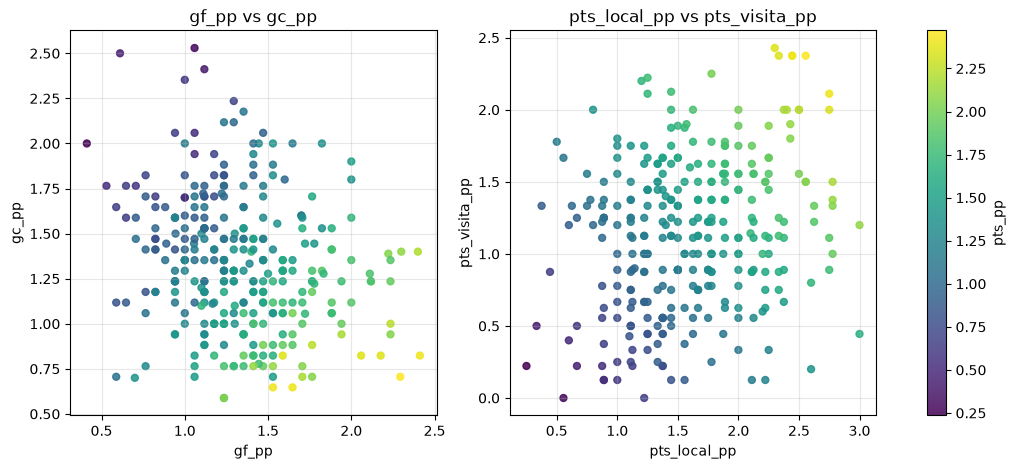

In [4]:
cols_final = ["gf_pp", "gc_pp", "empates_pp", "pts_local_pp", "pts_visita_pp"]

X_lm_z = pd.DataFrame(
    StandardScaler().fit_transform(ligamx[cols_final]),
    columns=cols_final, index=ligamx.index
)
print(X_lm_z.describe().loc[["mean", "std"]].round(3))

ligamx["pocos_partidos"] = (ligamx["partidos"] < 17).astype(int)
print("\nFilas con menos de 17 partidos:", ligamx["pocos_partidos"].sum())
print(ligamx.loc[ligamx["pocos_partidos"] == 1, "torneo"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="white")
for ax, (x, y) in zip(axes, [("gf_pp", "gc_pp"), ("pts_local_pp", "pts_visita_pp")]):
    sc = ax.scatter(ligamx[x], ligamx[y], c=ligamx["pts_pp"], cmap="viridis", s=25, alpha=0.85)
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}"); ax.set_facecolor("white"); ax.grid(alpha=0.3)
fig.colorbar(sc, ax=axes, label="pts_pp")
plt.show()

In [5]:
def hopkins(X, m, seed):
    X = np.asarray(X)
    n, d = X.shape
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]
    U = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, d))
    u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

def hopkins_rep(X, m, reps=50):
    h = [hopkins(X, m, s) for s in range(reps)]
    return np.mean(h), np.std(h)

X_all = X_lm_z.values
X_sin = X_lm_z[ligamx["pocos_partidos"] == 0].values   
m = int(0.1 * len(X_all))                              

unif = np.random.default_rng(0).uniform(size=X_all.shape)
normal = np.random.default_rng(0).multivariate_normal(
    mean=X_all.mean(axis=0), cov=np.cov(X_all.T), size=len(X_all))

resultados = {
    "Liga MX (307 filas)": hopkins_rep(X_all, m),
    "Liga MX sin 18 filas de 10 partidos": hopkins_rep(X_sin, m),
    "Referencia uniforme": hopkins_rep(unif, m),
    "Referencia normal (misma correlación)": hopkins_rep(normal, m),
}
for nombre, (media, desv) in resultados.items():
    print(f"{nombre:42s} {media:.3f} ± {desv:.3f}")

Liga MX (307 filas)                        0.703 ± 0.019
Liga MX sin 18 filas de 10 partidos        0.712 ± 0.020
Referencia uniforme                        0.491 ± 0.070
Referencia normal (misma correlación)      0.721 ± 0.018


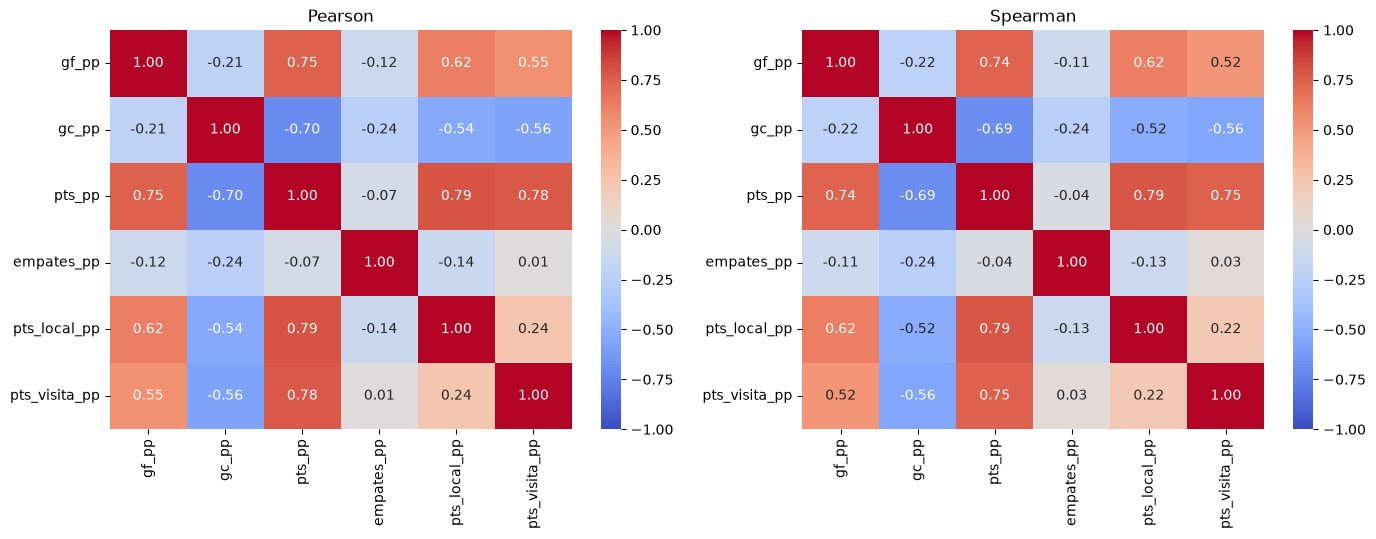

VIF con las 6 variables:


,variable,VIF
2,pts_pp,298.85
4,pts_local_pp,123.81
5,pts_visita_pp,114.99
1,gc_pp,4.27
0,gf_pp,4.16
3,empates_pp,1.32


VIF sin pts_pp (5 variables):


,variable,VIF
3,pts_local_pp,4.44
1,gc_pp,4.23
0,gf_pp,4.07
4,pts_visita_pp,3.69
2,empates_pp,1.32


In [6]:
cols6 = ["gf_pp", "gc_pp", "pts_pp", "empates_pp", "pts_local_pp", "pts_visita_pp"]
X6 = ligamx[cols6]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor="white")
sns.heatmap(X6.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson")
sns.heatmap(X6.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman")
plt.tight_layout()
plt.savefig("ligamx_colinealidad.png", dpi=200, facecolor="white")
plt.show()

def tabla_vif(df, columnas):
    Xc = add_constant(df[columnas])
    return pd.DataFrame({
        "variable": columnas,
        "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(len(columnas))]
    }).sort_values("VIF", ascending=False).round(2)

print("VIF con las 6 variables:");          display(tabla_vif(ligamx, cols6))
print("VIF sin pts_pp (5 variables):");     display(tabla_vif(ligamx, cols_final))

,k,inercia,silhouette,davies_bouldin,calinski_harabasz,caida_inercia
0,2,1062.752,0.263,1.401,135.531,NaN
1,3,851.741,0.243,1.357,121.933,211.011
2,4,756.654,0.215,1.464,103.896,95.088
3,5,682.741,0.215,1.340,94.246,73.912
4,6,622.503,0.199,1.390,88.244,60.238
5,7,577.771,0.197,1.359,82.838,44.732
6,8,550.803,0.195,1.367,76.324,26.969
7,9,507.970,0.187,1.354,75.313,42.833
8,10,474.215,0.201,1.350,73.819,33.755
9,11,449.854,0.199,1.287,71.402,24.361


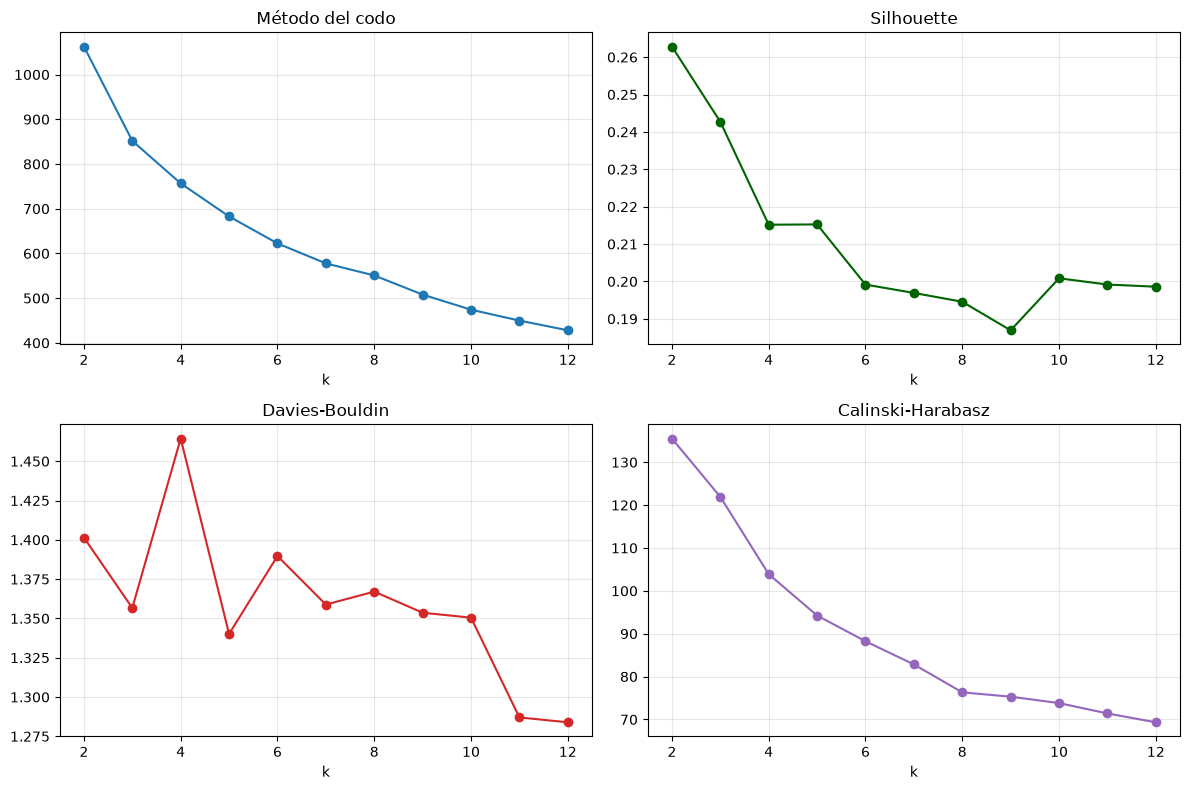

In [7]:
ks = range(2, 13)
filas = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etq = km.fit_predict(X_lm_z)
    filas.append({
        "k": k,
        "inercia": km.inertia_,
        "silhouette": silhouette_score(X_lm_z, etq),
        "davies_bouldin": davies_bouldin_score(X_lm_z, etq),
        "calinski_harabasz": calinski_harabasz_score(X_lm_z, etq),
    })
tabla_k = pd.DataFrame(filas)
tabla_k["caida_inercia"] = -tabla_k["inercia"].diff()
display(tabla_k.round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 8), facecolor="white")
for ax, (col, titulo, color) in zip(axes.ravel(), [
        ("inercia", "Método del codo", "tab:blue"),
        ("silhouette", "Silhouette", "darkgreen"),
        ("davies_bouldin", "Davies-Bouldin", "tab:red"),
        ("calinski_harabasz", "Calinski-Harabasz", "tab:purple")]):
    ax.plot(tabla_k["k"], tabla_k[col], "o-", color=color)
    ax.set_title(titulo); ax.set_xlabel("k")
    ax.set_facecolor("white"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

min_samples=6 | percentiles 50/75/90/95/99: [0.99 1.22 1.51 1.65 1.99]
min_samples=10 | percentiles 50/75/90/95/99: [1.15 1.37 1.74 1.94 2.27]


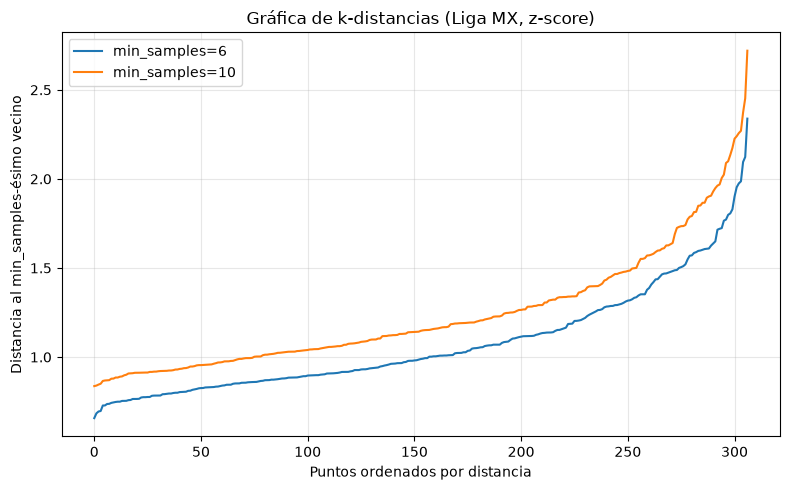

In [8]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
for ms in (6, 10):
    nn = NearestNeighbors(n_neighbors=ms).fit(X_lm_z)
    d = nn.kneighbors(X_lm_z)[0][:, -1]
    ax.plot(np.sort(d), label=f"min_samples={ms}")
    print(f"min_samples={ms} | percentiles 50/75/90/95/99:",
          np.percentile(d, [50, 75, 90, 95, 99]).round(2))

ax.set_title("Gráfica de k-distancias (Liga MX, z-score)")
ax.set_xlabel("Puntos ordenados por distancia")
ax.set_ylabel("Distancia al min_samples-ésimo vecino")
ax.set_facecolor("white"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("ligamx_kdist.png", dpi=200, facecolor="white")
plt.show()

In [9]:
filas = []
for ms in (6, 10):
    for eps in np.arange(0.7, 2.31, 0.2):
        etq = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_lm_z)
        ok = etq != -1
        filas.append({
            "min_samples": ms,
            "eps": round(eps, 1),
            "n_grupos": len(set(etq[ok])),
            "n_ruido": int((~ok).sum()),
            "% ruido": round(100 * (~ok).mean(), 1),
            "grupo_mayor": int(np.bincount(etq[ok]).max()) if ok.any() else 0,
        })
display(pd.DataFrame(filas))

,min_samples,eps,n_grupos,n_ruido,% ruido,grupo_mayor
0,6,0.7,3,286,93.2,9
1,6,0.9,2,115,37.5,186
2,6,1.1,1,44,14.3,263
3,6,1.3,1,19,6.2,288
4,6,1.5,1,5,1.6,302
5,6,1.7,1,2,0.7,305
6,6,1.9,1,1,0.3,306
7,6,2.1,1,0,0.0,307
8,6,2.3,1,0,0.0,307
9,10,0.7,0,307,100.0,0


In [10]:
filas = []
for ms, eps in [(6, 0.7), (6, 0.9), (10, 0.9)]:
    etq = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_lm_z)
    ok = etq != -1
    tamaños = sorted(np.bincount(etq[ok]), reverse=True)
    filas.append({
        "config": f"ms={ms}, eps={eps}",
        "n_grupos": len(tamaños),
        "tamaños de grupo": tamaños,
        "excluidos (ruido)": int((~ok).sum()),
        "Silhouette": silhouette_score(X_lm_z[ok], etq[ok]),
        "Davies-Bouldin": davies_bouldin_score(X_lm_z[ok], etq[ok]),
        "Calinski-Harabasz": calinski_harabasz_score(X_lm_z[ok], etq[ok]),
    })
display(pd.DataFrame(filas).set_index("config").round(3))

etq15 = DBSCAN(eps=1.5, min_samples=6).fit_predict(X_lm_z)
atipicos = ligamx.loc[etq15 == -1, ["equipo", "torneo", "partidos"] + cols_final + ["pts_pp"]]
display(atipicos.round(2))

,n_grupos,tamaños de grupo,excluidos (ruido),Silhouette,Davies-Bouldin,Calinski-Harabasz
config,,,,,,
"ms=6, eps=0.7",3,"[9, 6, 6]",286,0.531,0.643,53.014
"ms=6, eps=0.9",2,"[186, 6]",115,0.089,1.092,8.409
"ms=10, eps=0.9",4,"[43, 19, 13, 9]",223,0.236,1.090,36.776


,equipo,torneo,partidos,gf_pp,gc_pp,empates_pp,pts_local_pp,pts_visita_pp,pts_pp
133,Leon,2019-Clausura,10,2.30,1.40,0.00,3.00,1.20,2.10
152,Mazatlán,2022-Clausura,17,1.12,2.41,0.06,0.33,0.50,0.41
230,Puebla,2023-Clausura,17,1.06,2.53,0.12,0.56,0.00,0.29
233,Santos Laguna,2016-Clausura,17,1.47,1.18,0.65,2.11,0.88,1.53
301,Veracruz,2016-Clausura,17,0.82,1.18,0.00,2.25,0.33,1.24


Varianza explicada PC1, PC2: [0.472 0.242] | total: 0.714


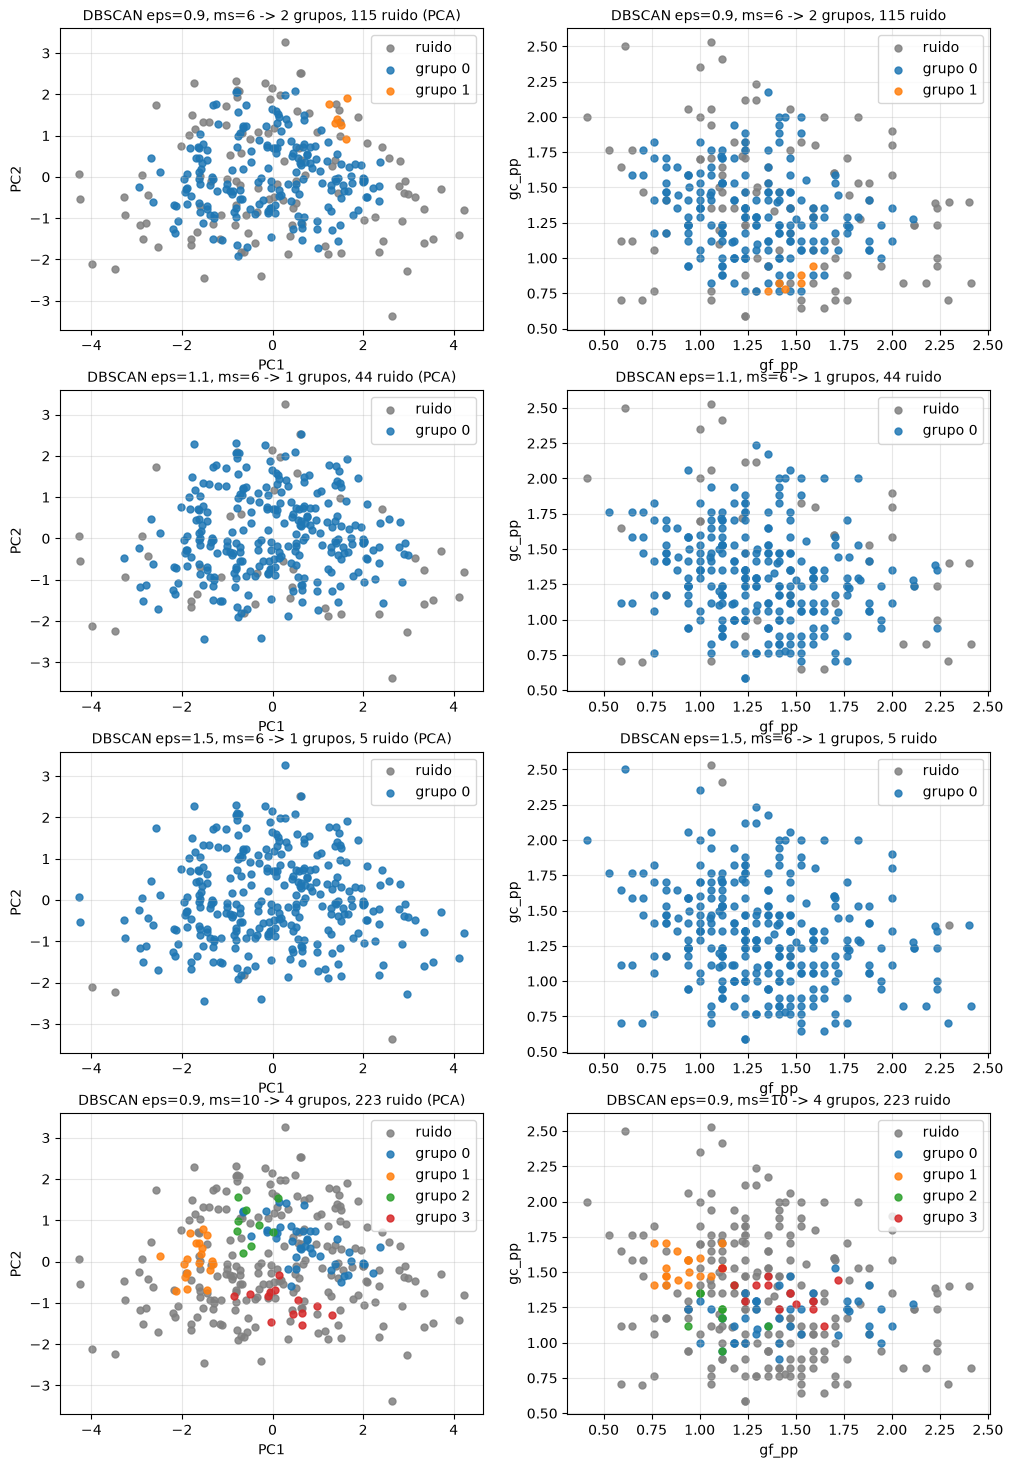

In [11]:
pca = PCA(n_components=2, random_state=42)
P_lm = pca.fit_transform(X_lm_z)
print("Varianza explicada PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

def graficar_2d(ax, P, etiquetas, titulo, xlab, ylab):
    etiquetas = np.asarray(etiquetas)
    for e in np.unique(etiquetas):
        m = etiquetas == e
        color = "gray" if e == -1 else plt.cm.tab10(int(e) % 10)
        nombre = "ruido" if e == -1 else f"grupo {e}"
        ax.scatter(P[m, 0], P[m, 1], s=25, color=color, label=nombre, alpha=0.85)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.set_facecolor("white"); ax.grid(alpha=0.3); ax.legend()

configs = [(6, 0.9), (6, 1.1), (6, 1.5), (10, 0.9)]

fig, axes = plt.subplots(len(configs), 2, figsize=(12, 4.5 * len(configs)), facecolor="white")
for fila, (ms, eps) in zip(axes, configs):
    etq = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_lm_z)
    n_gr = len(set(etq[etq != -1]))
    n_ru = int((etq == -1).sum())
    titulo = f"DBSCAN eps={eps}, ms={ms} -> {n_gr} grupos, {n_ru} ruido"
    graficar_2d(fila[0], P_lm, etq, titulo + " (PCA)", "PC1", "PC2")
    graficar_2d(fila[1], ligamx[["gf_pp", "gc_pp"]].values, etq, titulo, "gf_pp", "gc_pp")
plt.show()

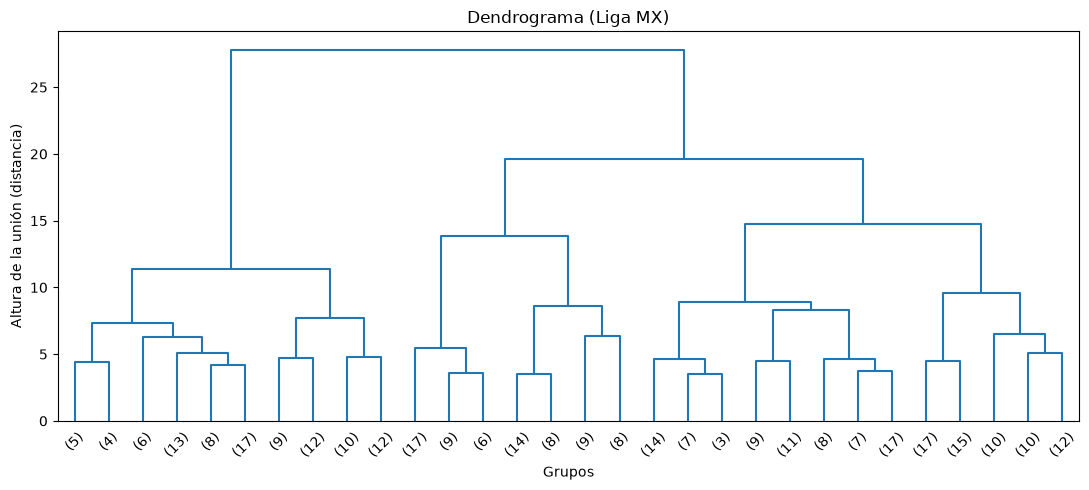

In [18]:
Z = linkage(X_lm_z, method="ward")
fig, ax = plt.subplots(figsize=(11, 5), facecolor="white")
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=0)
ax.set_title("Dendrograma (Liga MX)")
ax.set_xlabel("Grupos")
ax.set_ylabel("Altura de la unión (distancia)")
ax.set_facecolor("white")
plt.tight_layout()
plt.savefig("ligamx_dendrograma.png", dpi=200, facecolor="white")
plt.show()

,linkage,k,silhouette,davies_bouldin,calinski_harabasz,grupo_mayor
0,ward,2,0.223,1.443,102.556,211
1,ward,3,0.193,1.594,91.907,140
3,ward,5,0.160,1.487,78.681,96
11,complete,2,0.220,1.401,87.305,239
12,complete,3,0.169,1.593,86.196,158
14,complete,5,0.100,1.754,61.618,123
22,average,2,0.339,0.793,17.887,302
23,average,3,0.179,1.134,56.545,245
25,average,5,0.105,1.002,30.385,244
33,single,2,0.232,0.616,2.311,306


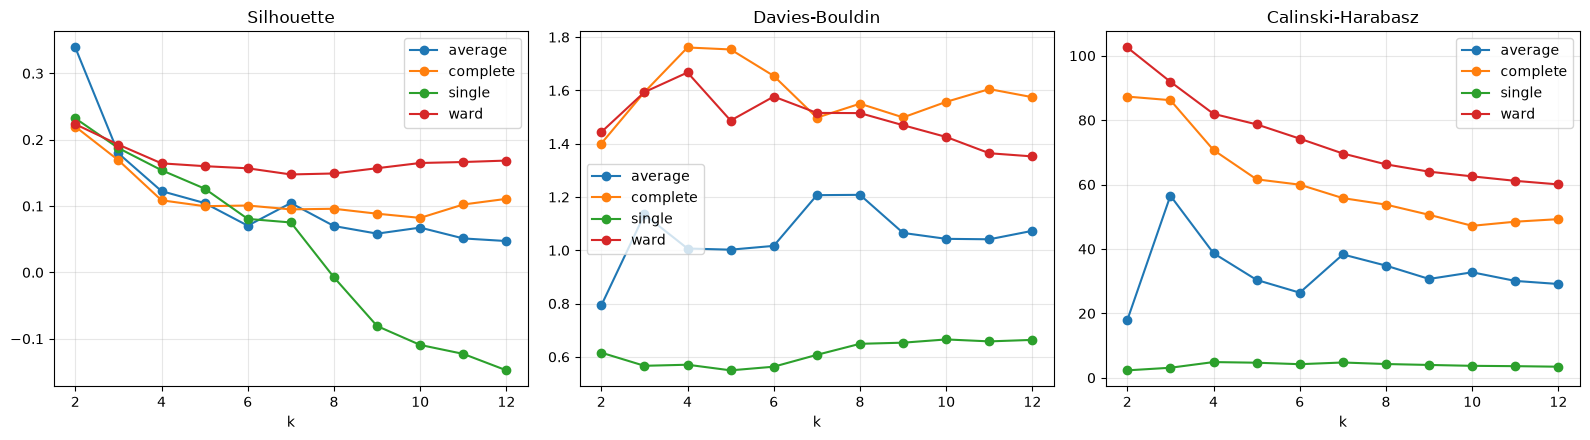

In [20]:
filas = []
for lk in ["ward", "complete", "average", "single"]:
    for k in range(2, 13):
        etq = AgglomerativeClustering(n_clusters=k, linkage=lk).fit_predict(X_lm_z)
        filas.append({
            "linkage": lk, "k": k,
            "silhouette": silhouette_score(X_lm_z, etq),
            "davies_bouldin": davies_bouldin_score(X_lm_z, etq),
            "calinski_harabasz": calinski_harabasz_score(X_lm_z, etq),
            "grupo_mayor": int(np.bincount(etq).max()),
        })
tabla_jer = pd.DataFrame(filas)
display(tabla_jer[tabla_jer["k"].isin([2, 3, 5])].round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), facecolor="white")
for ax, (col, titulo) in zip(axes, [("silhouette", "Silhouette"),
                                    ("davies_bouldin", "Davies-Bouldin"),
                                    ("calinski_harabasz", "Calinski-Harabasz")]):
    for lk, g in tabla_jer.groupby("linkage"):
        ax.plot(g["k"], g[col], "o-", label=lk)
    ax.set_title(titulo); ax.set_xlabel("k")
    ax.set_facecolor("white"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("ligamx_jerarquico_metricas.png", dpi=200, facecolor="white")
plt.show()

In [14]:
filas = []
for xi in (2, 3, 4, 5, 6):
    for tau in (0, 1, 2, 3, 5):
        c = clique(X_lm_z.values.tolist(), xi, tau)
        c.process()
        grupos = c.get_clusters()
        ruido = c.get_noise()
        tam = sorted([len(g) for g in grupos], reverse=True)
        filas.append({
            "intervalos": xi, "umbral": tau, "celdas": xi**5,
            "n_grupos": len(grupos), "n_ruido": len(ruido),
            "% ruido": round(100 * len(ruido) / len(X_lm_z), 1),
            "grupo_mayor": tam[0] if tam else 0,
            "tamaños (top 5)": tam[:5],
        })
display(pd.DataFrame(filas))

,intervalos,umbral,celdas,n_grupos,n_ruido,% ruido,grupo_mayor,tamaños (top 5)
0,2,0,32,1,0,0.0,307,[307]
1,2,1,32,1,6,2.0,301,[301]
2,2,2,32,1,10,3.3,297,[297]
3,2,3,32,1,10,3.3,297,[297]
4,2,5,32,1,28,9.1,279,[279]
5,3,0,243,2,0,0.0,306,"[306, 1]"
6,3,1,243,1,23,7.5,284,[284]
7,3,2,243,1,63,20.5,244,[244]
8,3,3,243,1,102,33.2,205,[205]
9,3,5,243,2,159,51.8,142,"[142, 6]"


,grupos,tamaños de grupo,excluidos (ruido),Silhouette,Davies-Bouldin,Calinski-Harabasz
config,,,,,,
"intervalos=3, umbral=5",2,"[142, 6]",159,0.177,1.044,10.700
"intervalos=4, umbral=1",3,"[221, 3, 2]",81,0.175,0.827,8.149
"intervalos=4, umbral=2",4,"[182, 6, 3, 3]",113,0.196,0.701,16.688
"intervalos=5, umbral=3",5,"[50, 4, 4, 4, 4]",241,0.027,1.249,8.591


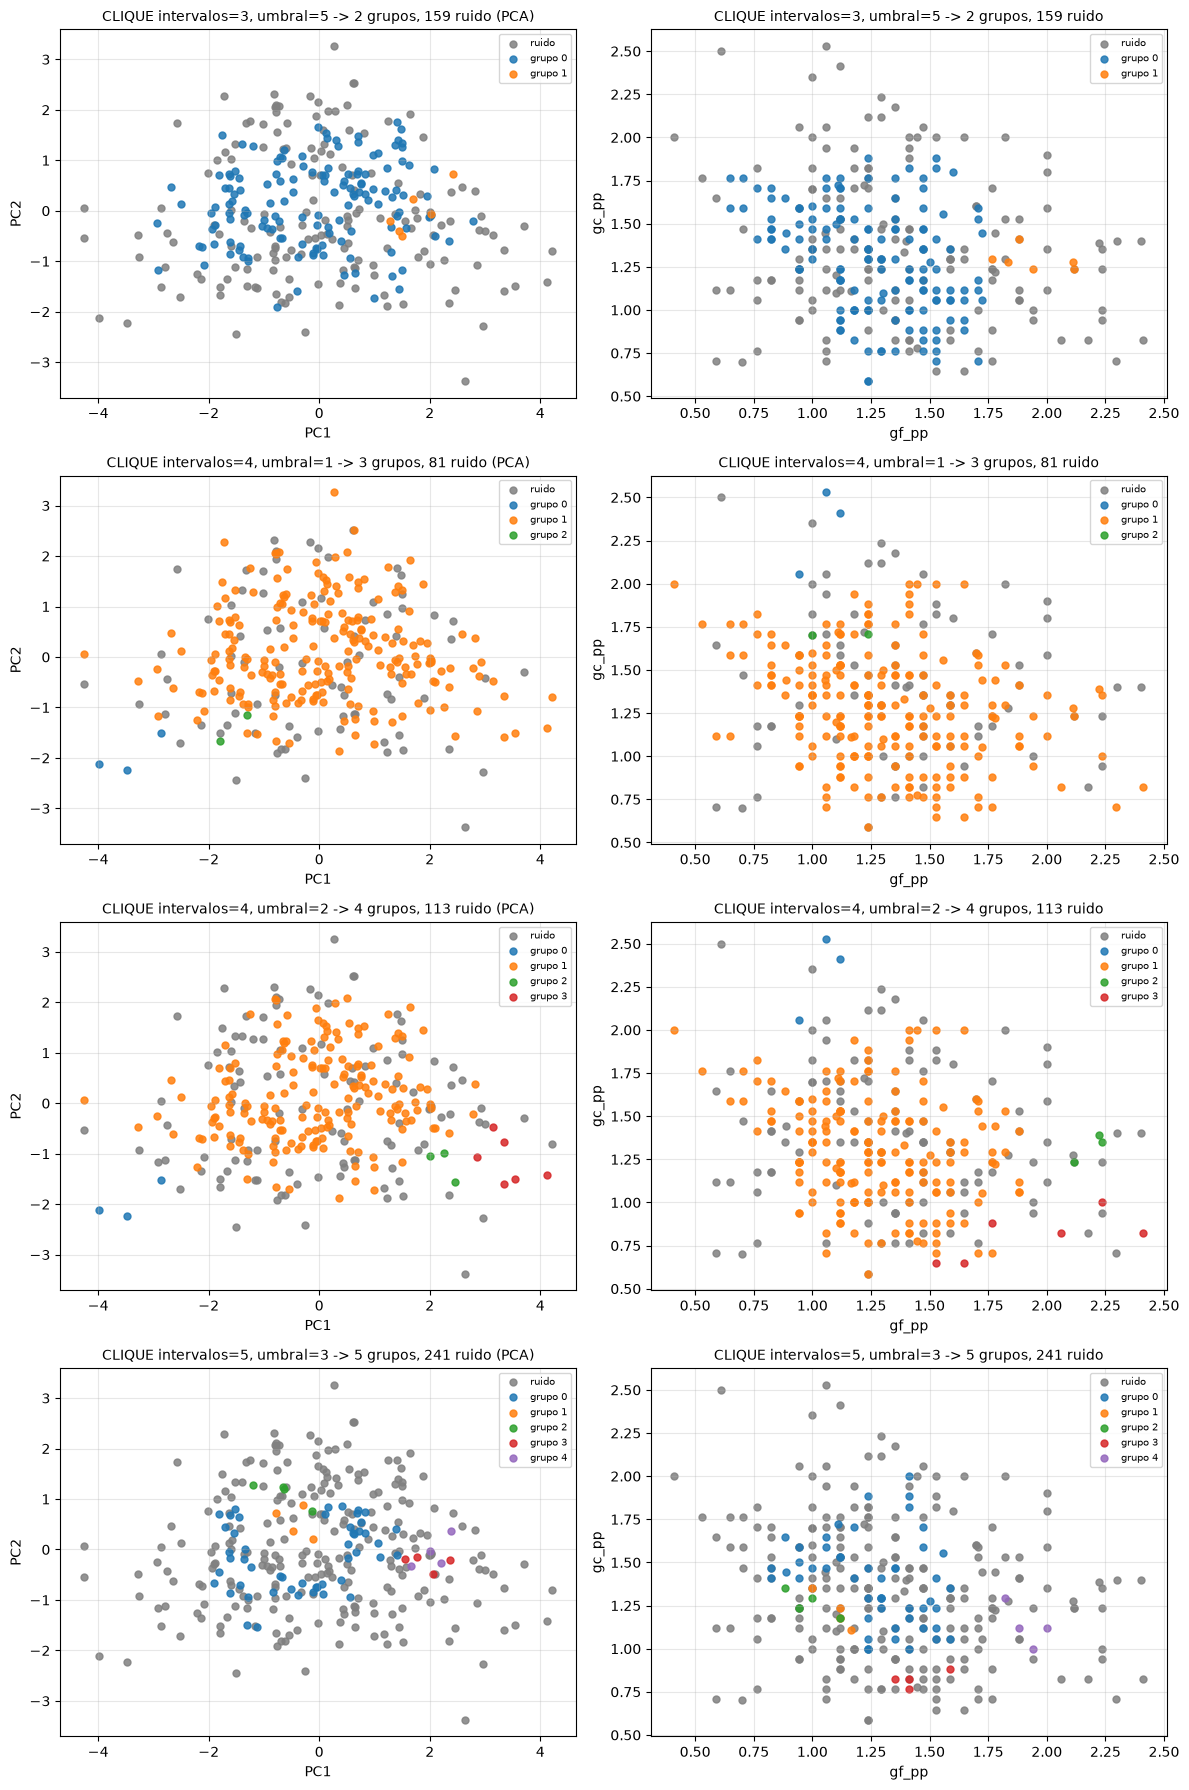

In [21]:
P_lm = PCA(n_components=2, random_state=42).fit_transform(X_lm_z)

def clique_etiquetas(X, xi, tau):
    """Devuelve un arreglo con el grupo de cada punto (-1 = ruido)."""
    c = clique(X.values.tolist(), xi, tau)
    c.process()
    etq = np.full(len(X), -1)
    for g, idx in enumerate(c.get_clusters()):
        etq[idx] = g
    return etq

def graficar_2d(ax, P, etiquetas, titulo, xlab, ylab):
    etiquetas = np.asarray(etiquetas)
    for e in np.unique(etiquetas):
        m = etiquetas == e
        color = "gray" if e == -1 else plt.cm.tab10(int(e) % 10)
        nombre = "ruido" if e == -1 else f"grupo {e}"
        ax.scatter(P[m, 0], P[m, 1], s=25, color=color, label=nombre, alpha=0.85)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.set_facecolor("white"); ax.grid(alpha=0.3); ax.legend(fontsize=7)

configs = [(3, 5), (4, 1), (4, 2), (5, 3)]
filas, etqs = [], {}
for xi, tau in configs:
    etq = clique_etiquetas(X_lm_z, xi, tau)
    etqs[(xi, tau)] = etq
    ok = etq != -1
    tam = sorted(np.bincount(etq[ok]), reverse=True)
    filas.append({
        "config": f"intervalos={xi}, umbral={tau}",
        "grupos": len(tam),
        "tamaños de grupo": tam,
        "excluidos (ruido)": int((~ok).sum()),
        "Silhouette": silhouette_score(X_lm_z[ok], etq[ok]),
        "Davies-Bouldin": davies_bouldin_score(X_lm_z[ok], etq[ok]),
        "Calinski-Harabasz": calinski_harabasz_score(X_lm_z[ok], etq[ok]),
    })
display(pd.DataFrame(filas).set_index("config").round(3))

fig, axes = plt.subplots(len(configs), 2, figsize=(12, 4.5 * len(configs)), facecolor="white")
for fila, (xi, tau) in zip(axes, configs):
    etq = etqs[(xi, tau)]
    n_gr = len(set(etq[etq != -1])); n_ru = int((etq == -1).sum())
    titulo = f"CLIQUE intervalos={xi}, umbral={tau} -> {n_gr} grupos, {n_ru} ruido"
    graficar_2d(fila[0], P_lm, etq, titulo + " (PCA)", "PC1", "PC2")
    graficar_2d(fila[1], ligamx[["gf_pp", "gc_pp"]].values, etq, titulo, "gf_pp", "gc_pp")
plt.tight_layout()
plt.savefig("ligamx_clique.png", dpi=200, facecolor="white")
plt.show()

In [16]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, silhouette_score,
                             davies_bouldin_score, calinski_harabasz_score)
cols_final = ["gf_pp", "gc_pp", "empates_pp", "pts_local_pp", "pts_visita_pp"]
ligamx["pocos_partidos"] = (ligamx["partidos"] < 17).astype(int)
mask = (ligamx["pocos_partidos"] == 0).values            # True = filas con 17 o más partidos

X_lm_z = pd.DataFrame(StandardScaler().fit_transform(ligamx[cols_final]),
                      columns=cols_final, index=ligamx.index)
X_sin = pd.DataFrame(StandardScaler().fit_transform(ligamx.loc[mask, cols_final]),
                     columns=cols_final)                  # se reestandariza sin las 18

# 1. ¿Se comportan distinto las 18 filas?
display(ligamx.groupby("pocos_partidos")[cols_final].agg(["mean", "std"]).round(2).T)

# 2. K-Means con y sin las 18 filas, y referencia quitando 18 al azar
rng = np.random.default_rng(0)
filas = []
for k in (2, 3, 5):
    etq_todas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_lm_z)
    etq_sin = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_sin)
    ari_real = adjusted_rand_score(etq_todas[mask], etq_sin)

    aris = []
    for _ in range(20):
        quitar = rng.choice(len(ligamx), 18, replace=False)
        m = np.ones(len(ligamx), dtype=bool); m[quitar] = False
        Xs = pd.DataFrame(StandardScaler().fit_transform(ligamx.loc[m, cols_final]),
                          columns=cols_final)
        e_s = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
        aris.append(adjusted_rand_score(etq_todas[m], e_s))

    filas.append({
        "k": k,
        "ARI quitando las 18": ari_real,
        "ARI quitando 18 al azar (media)": np.mean(aris),
        "ARI quitando 18 al azar (mínimo)": np.min(aris),
        "Silhouette (todas)": silhouette_score(X_lm_z, etq_todas),
        "Silhouette (sin las 18)": silhouette_score(X_sin, etq_sin),
        "Davies-Bouldin (todas)": davies_bouldin_score(X_lm_z, etq_todas),
        "Davies-Bouldin (sin las 18)": davies_bouldin_score(X_sin, etq_sin),
        "Calinski-H. (todas)": calinski_harabasz_score(X_lm_z, etq_todas),
        "Calinski-H. (sin las 18)": calinski_harabasz_score(X_sin, etq_sin),
    })
display(pd.DataFrame(filas).set_index("k").round(3).T)

pocos_partidos         0     1
gf_pp         mean  1.32  1.44
              std   0.36  0.48
gc_pp         mean  1.32  1.44
              std   0.37  0.32
empates_pp    mean  0.27  0.23
              std   0.11  0.13
pts_local_pp  mean  1.60  1.53
              std   0.53  0.76
pts_visita_pp mean  1.13  1.22
              std   0.52  0.60

k,2,3,5
ARI quitando las 18,0.932,0.937,0.500
ARI quitando 18 al azar (media),0.972,0.955,0.749
ARI quitando 18 al azar (mínimo),0.918,0.899,0.408
Silhouette (todas),0.263,0.243,0.215
Silhouette (sin las 18),0.274,0.253,0.191
Davies-Bouldin (todas),1.401,1.357,1.340
Davies-Bouldin (sin las 18),1.354,1.298,1.452
Calinski-H. (todas),135.531,121.933,94.246
Calinski-H. (sin las 18),138.243,124.037,93.036


,grupos,tamaños (top 4),excluidos,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
técnica,,,,,,
K-Means (k=3),3,"[112, 102, 93]",0,0.243,1.357,121.933
Jerárquico Ward (k=3),3,"[140, 96, 71]",0,0.193,1.594,91.907
"DBSCAN (eps=0.9, ms=6)",2,"[186, 6]",115,0.089,1.092,8.409
"CLIQUE (4 interv., umbral 2)",4,"[182, 6, 3, 3]",113,0.196,0.701,16.688


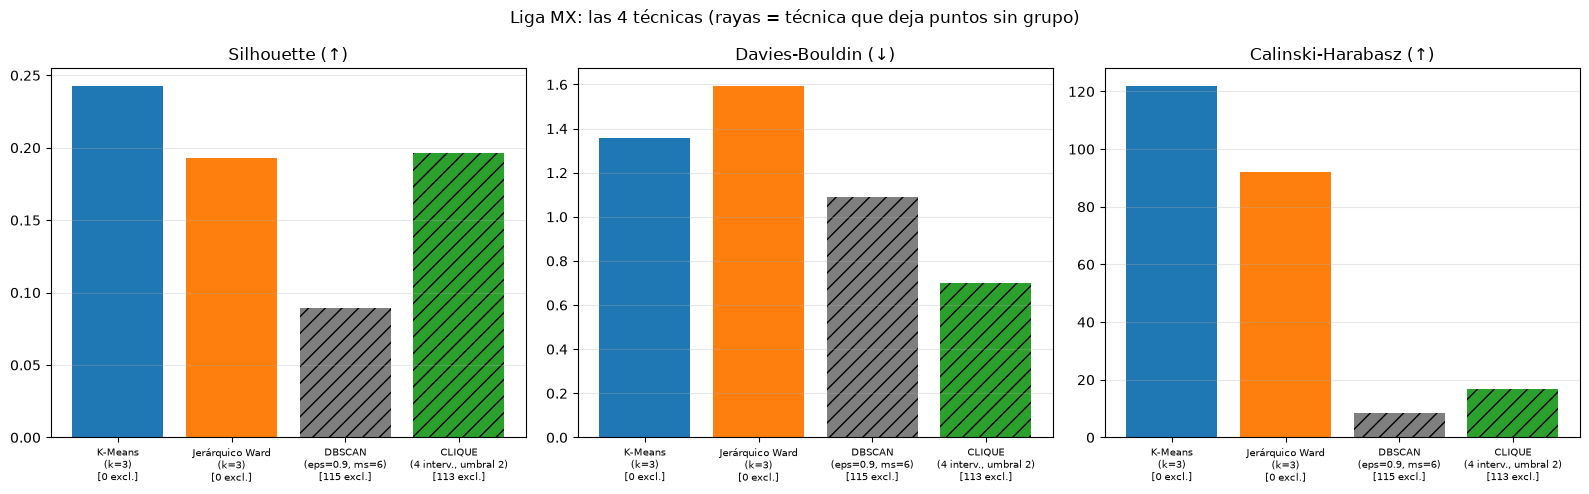

In [17]:
cols_final = ["gf_pp", "gc_pp", "empates_pp", "pts_local_pp", "pts_visita_pp"]
X_lm_z = pd.DataFrame(StandardScaler().fit_transform(ligamx[cols_final]),
                      columns=cols_final, index=ligamx.index)

def clique_etiquetas(X, xi, tau):
    c = clique(X.values.tolist(), xi, tau)
    c.process()
    etq = np.full(len(X), -1)
    for g, idx in enumerate(c.get_clusters()):
        etq[idx] = g
    return etq

resultados = {
    "K-Means\n(k=3)": KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_lm_z),
    "Jerárquico Ward\n(k=3)": AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_lm_z),
    "DBSCAN\n(eps=0.9, ms=6)": DBSCAN(eps=0.9, min_samples=6).fit_predict(X_lm_z),
    "CLIQUE\n(4 interv., umbral 2)": clique_etiquetas(X_lm_z, 4, 2),
}

filas = []
for nombre, etq in resultados.items():
    ok = etq != -1                                   # puntos que sí tienen grupo
    tam = sorted(np.bincount(etq[ok]), reverse=True)
    filas.append({
        "técnica": nombre.replace("\n", " "),
        "grupos": len(tam),
        "tamaños (top 4)": tam[:4],
        "excluidos": int((~ok).sum()),
        "Silhouette (↑)": silhouette_score(X_lm_z[ok], etq[ok]),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_lm_z[ok], etq[ok]),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X_lm_z[ok], etq[ok]),
    })
tabla_final = pd.DataFrame(filas).set_index("técnica")
display(tabla_final.round(3))

# Gráfica: barras con rayas en las técnicas que dejan puntos sin grupo
nombres = list(resultados.keys())
excl = tabla_final["excluidos"].values
etiquetas_x = [f"{n}\n[{e} excl.]" for n, e in zip(nombres, excl)]
colores = ["tab:blue", "tab:orange", "tab:gray", "tab:green"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), facecolor="white")
for ax, col in zip(axes, ["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]):
    barras = ax.bar(range(4), tabla_final[col].values, color=colores)
    for b, e in zip(barras, excl):
        if e > 0:
            b.set_hatch("//")
    ax.set_xticks(range(4)); ax.set_xticklabels(etiquetas_x, fontsize=7)
    ax.set_title(col); ax.set_facecolor("white"); ax.grid(axis="y", alpha=0.3)
plt.suptitle("Liga MX: las 4 técnicas (rayas = técnica que deja puntos sin grupo)")
plt.tight_layout()
plt.savefig("ligamx_comparacion_final.png", dpi=200, facecolor="white")
plt.show()